# Multi Unconfoundedness: GATET

An adaptation of `gate.ipynb` for `MultiTreatmentIRM`: estimate heterogeneous effects of multiple treatments among clients who received **a specific treatment**.

We compare two product interventions (`d_1`, `d_2`) with no intervention (`d_0`). The outcome `y` is a continuous, positive activity metric. For each intervention, we first estimate the overall average treatment effect on the treated (ATTE), then group average treatment effects on the treated (GATET).

$$\theta_{g,k}=\mathbb{E}[Y(k)-Y(0)\mid G=g,D=k],\qquad k\in\{1,2\}.$$

GATET for `d_1` and `d_2` refers to different client populations. Their difference alone is not the effect of switching from `d_1` to `d_2` in a common population.

## Data

We use Causalis' `generate_multitreatment_gamma_26`: three mutually exclusive treatment arms, eight confounders, a Gamma-distributed outcome, and heterogeneous effects. The sample size and seed are explicit so the example can be reproduced in a moderate amount of time.

The oracle columns contain the generator's known conditional effects. They are used only to check the results and are excluded from the model features.

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from causalis.scenarios.multi_unconfoundedness.dgp import generate_multitreatment_gamma_26

SEED = 42
N = 12_000
TREATMENTS = ["d_0", "d_1", "d_2"]
ACTIVE_ARMS = TREATMENTS[1:]
CONFOUNDERS = [
    "tenure_months", "avg_sessions_week", "spend_last_month", "premium_user",
    "urban_resident", "support_tickets_q", "discount_eligible", "credit_utilization",
]
pd.set_option("display.max_columns", 30)

raw_data = generate_multitreatment_gamma_26(
    n=N, seed=SEED, return_causal_data=False, include_oracle=True,
)
raw_data["user_id"] = [f"client_{i:05d}" for i in range(len(raw_data))]
raw_data[TREATMENTS + ["user_id", "y"] + CONFOUNDERS].head()

,d_0,d_1,d_2,user_id,y,tenure_months,avg_sessions_week,spend_last_month,premium_user,urban_resident,support_tickets_q,discount_eligible,credit_utilization
0,0.0,1.0,0.0,client_00000,1.221225,27.656605,3.198667,89.609464,0.0,1.0,0.0,1.0,0.401564
1,1.0,0.0,0.0,client_00001,1.831766,23.798386,3.362415,102.337236,0.0,0.0,3.0,0.0,0.383872
2,0.0,1.0,0.0,client_00002,0.602212,28.425009,3.391819,102.660712,0.0,1.0,1.0,0.0,0.464129
3,1.0,0.0,0.0,client_00003,0.997225,18.860066,4.071175,83.593417,0.0,0.0,2.0,0.0,0.479544
4,1.0,0.0,0.0,client_00004,6.081821,17.853087,3.140075,79.209870,0.0,1.0,1.0,1.0,0.484362


In [27]:
oracle_global = pd.DataFrame({
    "treatment": ACTIVE_ARMS,
    "oracle_ATE": [raw_data[f"cate_{arm}"].mean() for arm in ACTIVE_ARMS],
    "oracle_ATTE": [
        raw_data.loc[raw_data[arm].eq(1), f"cate_{arm}"].mean()
        for arm in ACTIVE_ARMS
    ],
}).set_index("treatment")
oracle_global

,oracle_ATE,oracle_ATTE
treatment,,
d_1,-1.199463,-1.309649
d_2,2.537968,2.677048


Here, `oracle_ATTE` averages the known conditional effect over the actual recipients of each treatment in the generated sample. It is a sample-specific benchmark; inclusion in a confidence interval in a single run does not validate nominal coverage.

In [28]:
from causalis.data_contracts import MultiCausalData

causaldata = MultiCausalData(
    df=raw_data,
    treatment_names=TREATMENTS,
    control_treatment="d_0",
    user_id="user_id",
    outcome="y",
    confounders=CONFOUNDERS,
)
# Set IDs before fitting so groups can be aligned to the training observations.
data = causaldata.df.set_index("user_id", drop=False)
assert data.index.is_unique
assert data[TREATMENTS].sum(axis=1).eq(1).all()
causaldata

MultiCausalData(df=(12000, 13), treatment_names=['d_0', 'd_1', 'd_2'], control_treatment='d_0')outcome='y', confounders=['tenure_months', 'avg_sessions_week', 'spend_last_month', 'premium_user', 'urban_resident', 'support_tickets_q', 'discount_eligible', 'credit_utilization'], user_id='user_id', 

## Exploratory data analysis

In [29]:
from causalis.shared import outcome_stats

outcome_stats(causaldata)

,treatment,count,mean,std,min,p10,p25,median,p75,p90,max
0,d_1,2953,2.986028,2.448562,0.032307,0.692534,1.286519,2.335231,3.950240,5.981958,29.149891
1,d_0,6054,3.777767,3.087870,0.031581,0.834758,1.599323,2.954446,5.092518,7.695151,34.162179
2,d_2,2993,6.646957,5.624064,0.037441,1.512151,2.793525,5.157652,8.711322,13.569910,46.676498


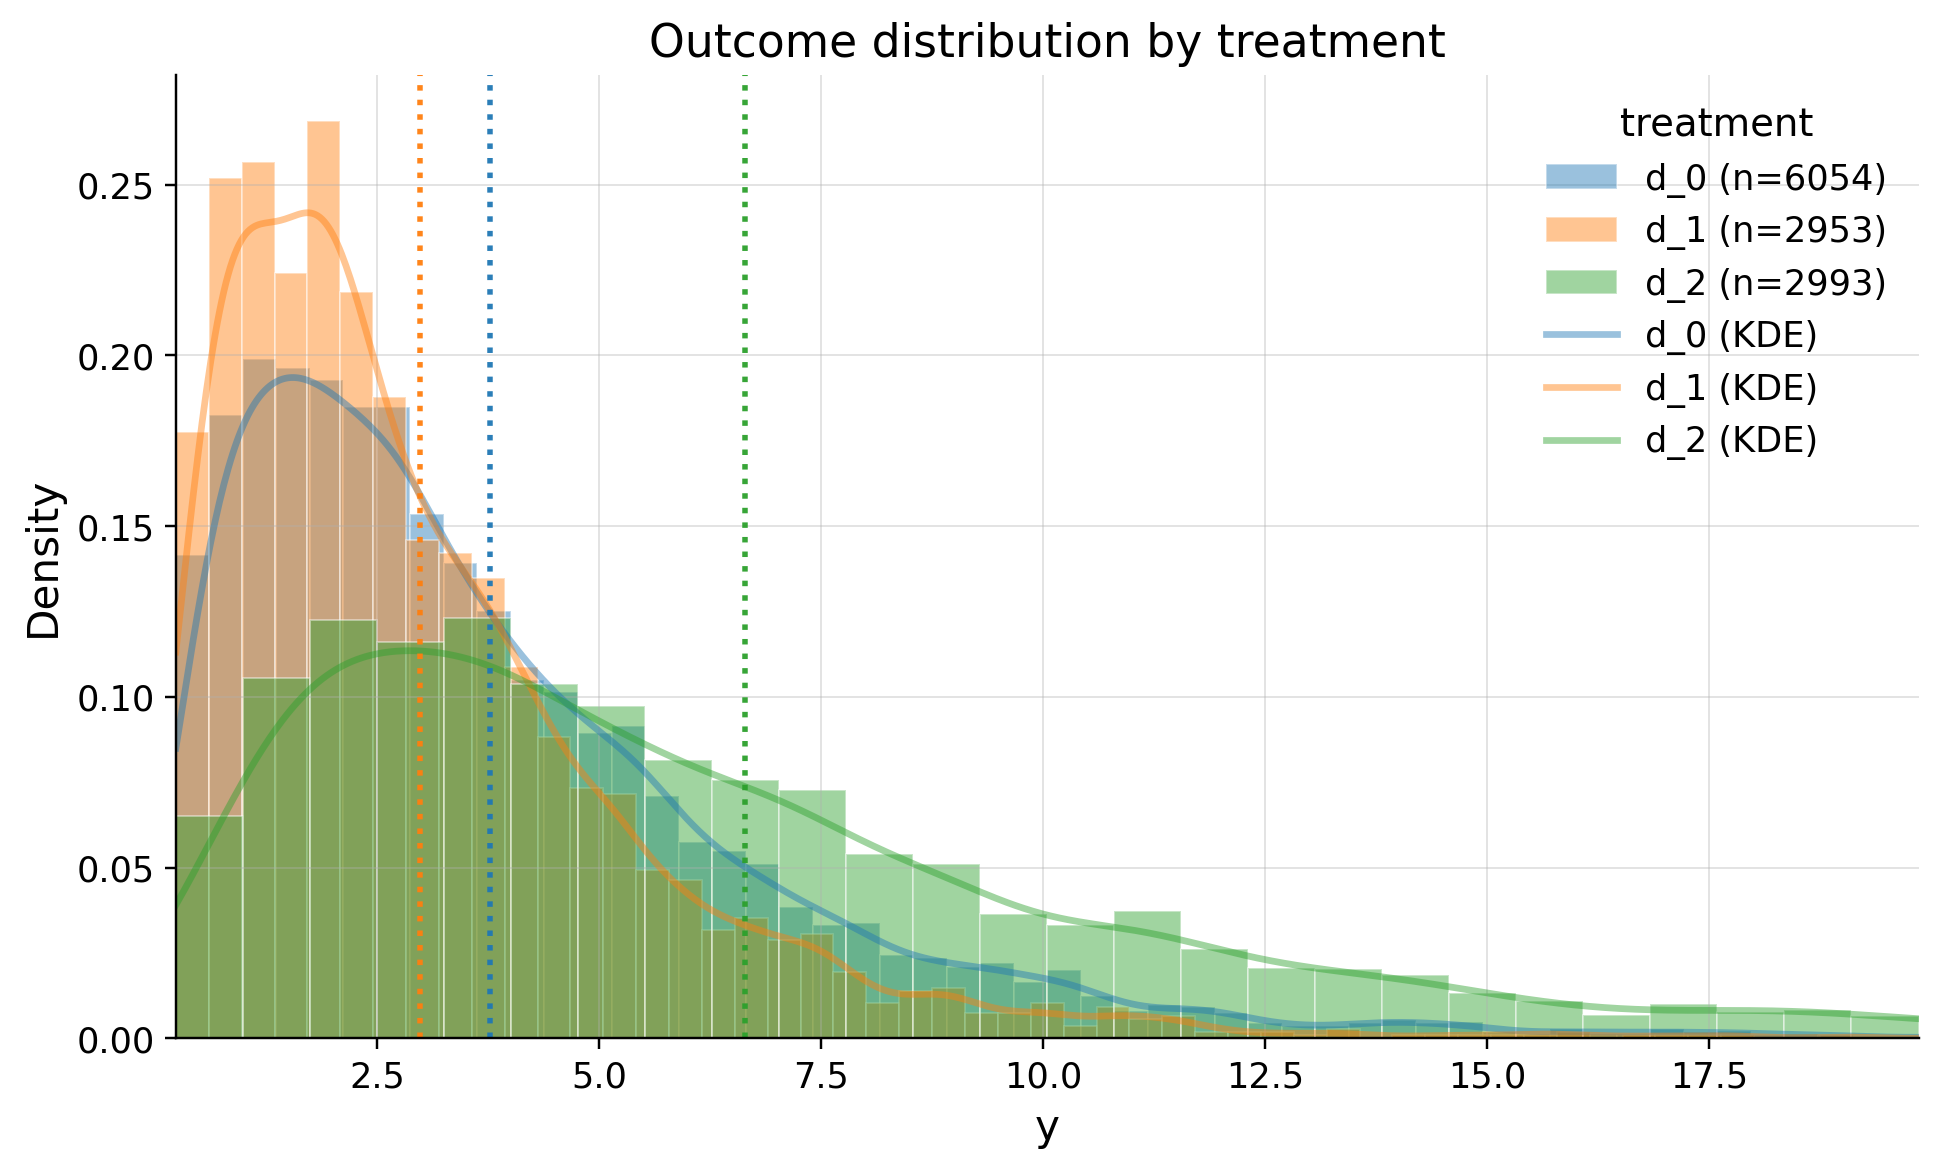

In [30]:
from causalis.shared.outcome_plots import outcome_plot_dist

outcome_plot_dist(causaldata)

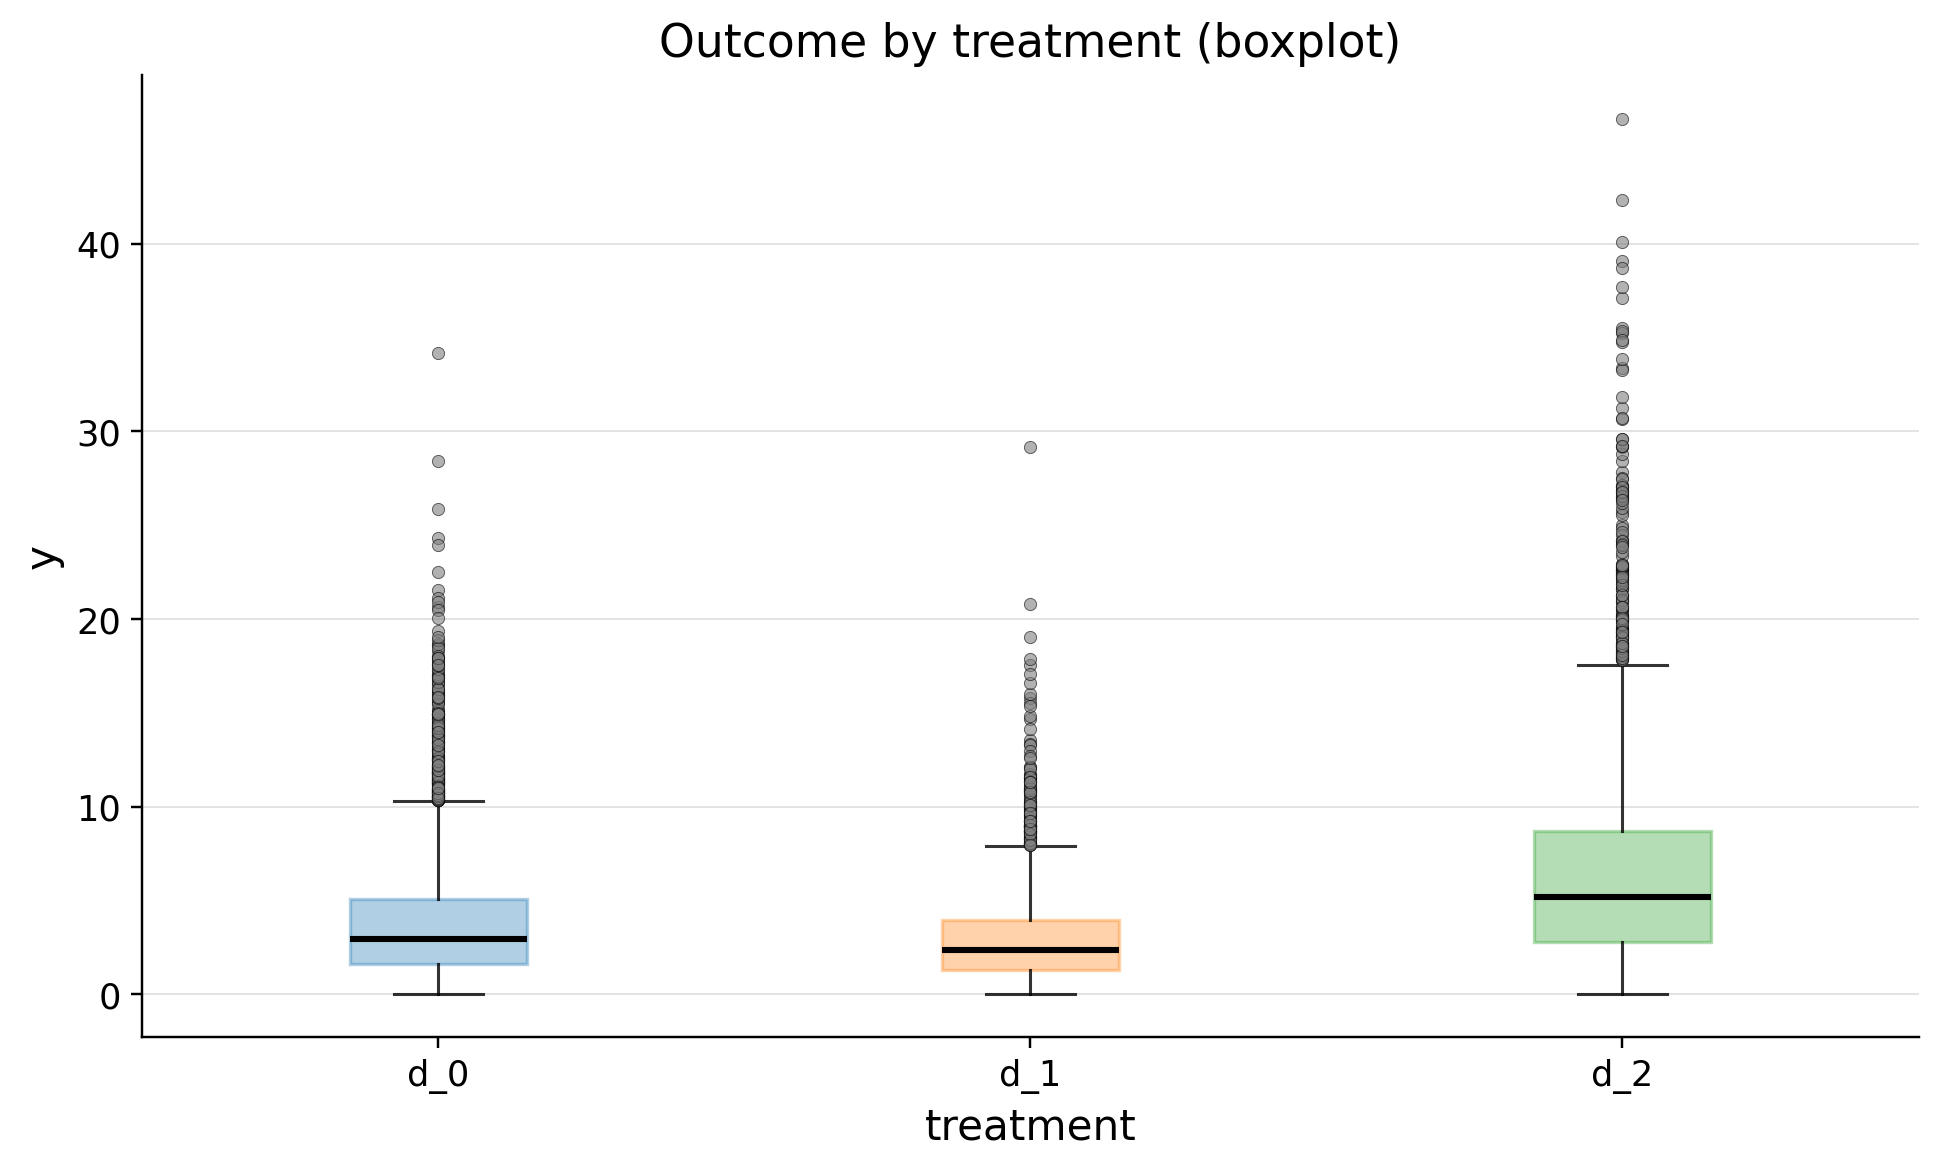

In [31]:
from causalis.shared.outcome_plots import outcome_plot_boxplot

outcome_plot_boxplot(causaldata)

In [32]:
from causalis.shared import outcome_outliers

outcome_outliers(causaldata)

,treatment,n,outlier_count,outlier_rate,lower_bound,upper_bound,has_outliers,method,tail
0,d_1,2953,125,0.042330,-2.709062,7.945821,True,iqr,both
1,d_0,6054,237,0.039148,-3.640469,10.332310,True,iqr,both
2,d_2,2993,155,0.051788,-6.083171,17.588018,True,iqr,both


The generator produces a positive outcome with a right tail. We retain all observations: removing clients based on their observed outcome would change the analysis sample and could introduce selection bias. Observed differences in arm means also reflect differences in client composition; they are not causal effect estimates.

In [33]:
from causalis.shared import confounders_balance

for arm in ACTIVE_ARMS:
    print(f"Confounder balance: {arm} vs d_0")
    display(confounders_balance(causaldata, "d_0", arm).rename(
        columns={"mean_d_1": f"mean_{arm}"},
    ))

Confounder balance: d_1 vs d_0


,confounders,mean_d_0,mean_d_1,abs_diff,smd,ks_pvalue
0,avg_sessions_week,4.780385,5.207320,0.426935,0.215049,0.00000
1,premium_user,0.227288,0.315611,0.088323,0.199571,0.00000
2,discount_eligible,0.338454,0.421267,0.082813,0.171226,0.00000
3,tenure_months,23.721367,25.413321,1.691955,0.143832,0.00000
4,spend_last_month,80.484371,89.064397,8.580026,0.101790,0.00207
5,urban_resident,0.580278,0.627836,0.047559,0.097349,0.00024
6,credit_utilization,0.449721,0.448029,0.001692,-0.015389,0.55756
7,support_tickets_q,1.548563,1.564172,0.015609,0.012290,0.90580


Confounder balance: d_2 vs d_0


,confounders,mean_d_0,mean_d_2,abs_diff,smd,ks_pvalue
0,avg_sessions_week,4.780385,5.281892,0.501508,0.254290,0.00000
1,spend_last_month,80.484371,100.087293,19.602921,0.221317,0.00000
2,support_tickets_q,1.548563,1.387571,0.160992,-0.133825,0.00002
3,urban_resident,0.580278,0.641497,0.061219,0.125798,0.00000
4,premium_user,0.227288,0.235884,0.008596,0.020376,0.99811
5,discount_eligible,0.338454,0.347143,0.008689,0.018306,0.99778
6,credit_utilization,0.449721,0.451636,0.001915,0.017332,0.57797
7,tenure_months,23.721367,23.701077,0.020290,-0.001738,0.99033


## Overall ATTE: fit the model once

Identification assumes no unobserved confounding conditional on `CONFOUNDERS`, overlap between the compared arms, and SUTVA (consistent treatment definitions and no interference between clients). In particular, controls must be represented at covariate values found among recipients of each active treatment. All grouping features below are measured before treatment and are included in the confounder set. Segments are not selected using estimated effects or p-values.

`MultiTreatmentIRM` fits outcome models for each arm and one multiclass propensity model using cross-fitting. We explicitly limit CatBoost complexity and thread counts for reproducibility. These are teaching settings, not hyperparameters tuned on these data.

In [34]:
from catboost import CatBoostClassifier, CatBoostRegressor
from causalis.scenarios.multi_unconfoundedness import MultiTreatmentIRM

learner_options = dict(
    iterations=250, depth=5, learning_rate=0.05,
    random_seed=SEED, thread_count=2, verbose=False, allow_writing_files=False,
)
model = MultiTreatmentIRM(
    ml_g=CatBoostRegressor(loss_function="RMSE", **learner_options),
    ml_m=CatBoostClassifier(loss_function="MultiClass", **learner_options),
    n_folds=3, random_state=SEED, n_jobs=1,
    normalize_ipw=False, trimming_threshold=0.01,
).fit(causaldata)

In [35]:
atte_result = model.estimate(score="ATTE")
atte_result.summary()

,d_1 vs d_0,d_2 vs d_0
field,,
outcome,y,y
estimand,ATTE,ATTE
model,MultiTreatmentIRM,MultiTreatmentIRM
value,"-1.2794 (ci_abs: -1.4175, -1.1413)","2.5656 (ci_abs: 2.3425, 2.7888)"
value_relative,"-29.9946 (ci_rel: -32.5411, -27.4481)","62.8634 (ci_rel: 56.9953, 68.7315)"
alpha,0.0500,0.0500
p_value,0.0000,0.0000
is_significant,True,True
n_treated,2953,2993


In [36]:
atte_comparison = oracle_global.copy()
atte_comparison["estimated_ATTE"] = atte_result.value
atte_comparison["ci_lower"] = atte_result.ci_lower_absolute
atte_comparison["ci_upper"] = atte_result.ci_upper_absolute
atte_comparison["estimate_minus_oracle"] = (
    atte_comparison["estimated_ATTE"] - atte_comparison["oracle_ATTE"]
)
atte_comparison

,oracle_ATE,oracle_ATTE,estimated_ATTE,ci_lower,ci_upper,estimate_minus_oracle
treatment,,,,,,
d_1,-1.199463,-1.309649,-1.279399,-1.417487,-1.141311,0.030250
d_2,2.537968,2.677048,2.565649,2.342513,2.788784,-0.111399


## GATET: within-group effects among treatment recipients

For each active treatment $k$, we reuse the out-of-fold predictions:

$$z_{ik}=\left(D_{ik}-D_{i0}\frac{\hat e_k(X_i)}{\hat e_0(X_i)}\right)\bigl(Y_i-\hat\mu_0(X_i)\bigr),\qquad
\hat\theta_{g,k}=\frac{\sum_{i:G_i=g}z_{ik}}{n_{g,k}}.$$

Here, $D_{ik}$ indicates receipt of arm $k$, $\hat e_k$ is its fitted propensity (after the model's clipping and renormalization), and $\hat\mu_0$ is the fitted control outcome mean. Although fitting produces outcome predictions for all arms, GATET uses only the control outcome model.

The denominator $n_{g,k}$ is the number receiving **that treatment** within the group. Simply averaging the usual ATE signal over treated clients does not give GATET.

`groups` defines a partition of the entire sample. The API requires at least one recipient of every active treatment in every group. It allows groups without controls with a warning about degenerate overlap; this is not evidence that such estimates are reliable. For HC2/HC3, a cell with only one treated observation has undefined variance and NaN inference.

`n_control` counts only `d_0`; `n_other` counts the other active treatments. `normalize_ipw=True` is ignored for GATET with a warning. No model refitting is required.

### Quantile groups

Split clients into five groups by `tenure_months`. Quantiles are computed from this pre-treatment feature across the entire sample. Keep client IDs in the Series index. Inference treats the resulting partition as fixed; it does not separately account for uncertainty in estimated population quantile boundaries.

In [37]:
quantile_groups = pd.qcut(data["tenure_months"], q=5, duplicates="drop").rename("tenure_quantile")
quantile_result = model.estimate(score="GATET", groups=quantile_groups, cov_type="HC3")
# Equivalent shorthand: model.gatet(quantile_groups)
summary_columns = [
    "group", "treatment", "baseline_treatment", "value", "std_error",
    "ci_lower", "ci_upper", "p_value", "is_significant",
    "n_group", "n_treated", "n_control", "n_other",
]
quantile_result.summary()[summary_columns]

,group,treatment,baseline_treatment,value,std_error,ci_lower,ci_upper,p_value,is_significant,n_group,n_treated,n_control,n_other
0,"tenure_quantile=(-0.001, 13.89]",d_1,d_0,-0.666162,0.115326,-0.892197,-0.440127,7.634546e-09,True,2400,498,1269,633
1,"tenure_quantile=(-0.001, 13.89]",d_2,d_0,1.886728,0.174356,1.544998,2.228459,2.733260e-27,True,2400,633,1269,498
2,"tenure_quantile=(13.89, 21.003]",d_1,d_0,-1.245848,0.137451,-1.515246,-0.976449,1.257984e-19,True,2400,549,1233,618
3,"tenure_quantile=(13.89, 21.003]",d_2,d_0,2.355743,0.221931,1.920766,2.790720,2.544775e-26,True,2400,618,1233,549
4,"tenure_quantile=(21.003, 27.041]",d_1,d_0,-1.378303,0.142516,-1.657629,-1.098976,3.996548e-22,True,2400,610,1217,573
5,"tenure_quantile=(21.003, 27.041]",d_2,d_0,2.431256,0.237869,1.965041,2.897472,1.597381e-24,True,2400,573,1217,610
6,"tenure_quantile=(27.041, 34.125]",d_1,d_0,-1.393158,0.149519,-1.686210,-1.100106,1.190218e-20,True,2400,590,1194,616
7,"tenure_quantile=(27.041, 34.125]",d_2,d_0,2.909254,0.254640,2.410169,3.408340,3.137669e-30,True,2400,616,1194,590
8,"tenure_quantile=(34.125, 78.081]",d_1,d_0,-1.557531,0.174072,-1.898706,-1.216357,3.631752e-19,True,2400,706,1141,553
9,"tenure_quantile=(34.125, 78.081]",d_2,d_0,3.333867,0.296599,2.752544,3.915189,2.584221e-29,True,2400,553,1141,706


In [38]:
from causalis.scenarios.gate import gate_plot

fig, axes = plt.subplots(1, len(ACTIVE_ARMS), figsize=(14, 5))
for arm, ax in zip(ACTIVE_ARMS, axes):
    gate_plot(
        quantile_result.for_treatment(arm), ax=ax,
        title=f"GATET: {arm} vs d_0", xlabel="Effect on y",
    )
fig.tight_layout()

Each panel shows effects relative to `d_0` among recipients of its own treatment. The intervals and p-values in `summary()` are **pointwise**: they are not automatically adjusted across groups and treatments.

### Check against the generator's known effects

For each cell, average `cate_d_k` only over recipients of `d_k` in that group. Use group codes and IDs from the diagnostic data to reproduce the post-fit observation order exactly. Oracle effects are unavailable in real data.

In [39]:
def compare_with_oracle(result):
    diagnostics = result.diagnostic_data
    oracle = raw_data.set_index("user_id").loc[diagnostics["observation_ids"]]
    codes = diagnostics["group_codes"]
    records = []
    for group_position, group_name in enumerate(result.group_names):
        for arm in result.treatment_names:
            treated_in_group = (codes == group_position) & oracle[arm].eq(1).to_numpy()
            records.append({
                "group": group_name,
                "treatment": arm,
                "oracle_GATET": oracle.loc[treated_in_group, f"cate_{arm}"].mean(),
            })
    comparison = result.summary().merge(
        pd.DataFrame(records), on=["group", "treatment"], validate="one_to_one",
    )
    comparison["estimate_minus_oracle"] = comparison["value"] - comparison["oracle_GATET"]
    return comparison[[
        "group", "treatment", "value", "oracle_GATET", "estimate_minus_oracle",
        "ci_lower", "ci_upper", "n_treated",
    ]]

compare_with_oracle(quantile_result)

,group,treatment,value,oracle_GATET,estimate_minus_oracle,ci_lower,ci_upper,n_treated
0,"tenure_quantile=(-0.001, 13.89]",d_1,-0.666162,-0.926302,0.260140,-0.892197,-0.440127,498
1,"tenure_quantile=(-0.001, 13.89]",d_2,1.886728,2.027731,-0.141002,1.544998,2.228459,633
2,"tenure_quantile=(13.89, 21.003]",d_1,-1.245848,-1.142974,-0.102874,-1.515246,-0.976449,549
3,"tenure_quantile=(13.89, 21.003]",d_2,2.355743,2.346120,0.009623,1.920766,2.790720,618
4,"tenure_quantile=(21.003, 27.041]",d_1,-1.378303,-1.264710,-0.113593,-1.657629,-1.098976,610
5,"tenure_quantile=(21.003, 27.041]",d_2,2.431256,2.658852,-0.227595,1.965041,2.897472,573
6,"tenure_quantile=(27.041, 34.125]",d_1,-1.393158,-1.402120,0.008962,-1.686210,-1.100106,590
7,"tenure_quantile=(27.041, 34.125]",d_2,2.909254,2.959489,-0.050235,2.410169,3.408340,616
8,"tenure_quantile=(34.125, 78.081]",d_1,-1.557531,-1.671216,0.113685,-1.898706,-1.216357,706
9,"tenure_quantile=(34.125, 78.081]",d_2,3.333867,3.494359,-0.160492,2.752544,3.915189,553


### Binary groups

Use `premium_user`, available in the multi-treatment generator, in place of `mobile_user` from the original notebook. Convert values to integers to obtain stable group names: `premium_user=0` and `premium_user=1`.

In [40]:
binary_groups = data["premium_user"].astype(int).rename("premium_user")
binary_result = model.gatet(binary_groups)
binary_result.summary()[summary_columns]

,group,treatment,baseline_treatment,value,std_error,ci_lower,ci_upper,p_value,is_significant,n_group,n_treated,n_control,n_other
0,premium_user=0,d_1,d_0,-1.212822,0.075380,-1.360564,-1.065080,3.022656e-58,True,8986,2021,4678,2287
1,premium_user=0,d_2,d_0,2.355498,0.114244,2.131583,2.579412,1.888945e-94,True,8986,2287,4678,2021
2,premium_user=1,d_1,d_0,-1.423767,0.137505,-1.693273,-1.154262,4.001905e-25,True,3014,932,1376,706
3,premium_user=1,d_2,d_0,3.246408,0.256595,2.743492,3.749324,1.092144e-36,True,3014,706,1376,932


### Formal group comparisons

- `summary()` tests each cell's effect against zero.
- `for_treatment("d_1").contrast(...)` compares two groups within one treatment.
- `pairwise_summary(p_adjust="holm")` adjusts p-values within the returned set of comparisons for one treatment. It does not automatically cover other treatments or other partitions. The reported confidence intervals remain unadjusted; use `p_value_adj` and `is_significant_adj` for the adjusted decisions.

For the binary partition there is only one comparison per arm, so the within-arm Holm adjustment leaves its p-value unchanged. A significant effect in one group and a nonsignificant effect in another does not establish a difference between groups: an explicit contrast is required. These contrasts describe differences in treatment effects across recipient populations; they are not causal effects of changing premium status or tenure.

In [41]:
arm_result = binary_result.for_treatment("d_1")
arm_result.contrast("premium_user=1", "premium_user=0").summary()

,value
field,
estimand,GATET_CONTRAST
model,MultiTreatmentIRM
contrast,premium_user=1 - premium_user=0
left_group,premium_user=1
right_group,premium_user=0
value,"-0.2109 (ci_abs: -0.5183, 0.0964)"
std_error,0.1568
test_stat,-1.3452
alpha,0.0500


In [42]:
for arm in ACTIVE_ARMS:
    print(f"Premium versus non-premium comparison: {arm} vs d_0")
    display(binary_result.for_treatment(arm).pairwise_summary(
        reference="premium_user=0", p_adjust="holm",
    ))

Premium versus non-premium comparison: d_1 vs d_0


,left_group,right_group,contrast_label,left_value,right_value,estimate_diff,std_error,test_stat,p_value,p_value_adj,ci_lower,ci_upper,is_significant,is_significant_adj,n_left,n_right,alpha,p_adjust
0,premium_user=1,premium_user=0,premium_user=1 - premium_user=0,-1.423767,-1.212822,-0.210945,0.156811,-1.345217,0.178555,0.178555,-0.51829,0.096399,False,False,3014,8986,0.05,holm


Premium versus non-premium comparison: d_2 vs d_0


,left_group,right_group,contrast_label,left_value,right_value,estimate_diff,std_error,test_stat,p_value,p_value_adj,ci_lower,ci_upper,is_significant,is_significant_adj,n_left,n_right,alpha,p_adjust
0,premium_user=1,premium_user=0,premium_user=1 - premium_user=0,3.246408,2.355498,0.89091,0.280878,3.171874,0.001515,0.001515,0.340399,1.441421,True,True,3014,8986,0.05,holm


### Manually defined groups

Replace the original notebook's age groups with prespecified tenure intervals: less than 12 months, 12 to less than 36 months, and at least 36 months.

In [43]:
manual_groups = pd.Series(
    np.where(data["tenure_months"] < 12, "New",
             np.where(data["tenure_months"] < 36, "Established", "Long-term")),
    index=data.index,
    name="tenure_segment",
)
manual_result = model.gatet(manual_groups)
manual_result.summary()[summary_columns]

,group,treatment,baseline_treatment,value,std_error,ci_lower,ci_upper,p_value,is_significant,n_group,n_treated,n_control,n_other
0,tenure_segment=Established,d_1,d_0,-1.319837,0.078064,-1.472839,-1.166835,3.982933e-64,True,8147,1990,4117,2040
1,tenure_segment=Established,d_2,d_0,2.565073,0.129163,2.311918,2.818228,9.186637e-88,True,8147,2040,4117,1990
2,tenure_segment=Long-term,d_1,d_0,-1.556761,0.202703,-1.954051,-1.159471,1.590680e-14,True,1917,556,908,453
3,tenure_segment=Long-term,d_2,d_0,3.411210,0.330762,2.762928,4.059491,6.143064e-25,True,1917,453,908,556
4,tenure_segment=New,d_1,d_0,-0.702773,0.126252,-0.950224,-0.455323,2.600340e-08,True,1936,407,1029,500
5,tenure_segment=New,d_2,d_0,1.801920,0.191573,1.426443,2.177397,5.158458e-21,True,1936,500,1029,407


In [44]:
manual_result.for_treatment("d_2").pairwise_summary(p_adjust="holm")

,left_group,right_group,contrast_label,left_value,right_value,estimate_diff,std_error,test_stat,p_value,p_value_adj,ci_lower,ci_upper,is_significant,is_significant_adj,n_left,n_right,alpha,p_adjust
0,tenure_segment=Established,tenure_segment=Long-term,tenure_segment=Established - tenure_segment=Lo...,2.565073,3.41121,-0.846137,0.355087,-2.382901,0.017177,0.017177,-1.542094,-0.150179,True,True,8147,1917,0.05,holm
1,tenure_segment=Established,tenure_segment=New,tenure_segment=Established - tenure_segment=New,2.565073,1.80192,0.763153,0.231049,3.302996,0.000957,0.001913,0.310306,1.216000,True,True,8147,1936,0.05,holm
2,tenure_segment=Long-term,tenure_segment=New,tenure_segment=Long-term - tenure_segment=New,3.411210,1.80192,1.609290,0.382235,4.210207,0.000026,0.000077,0.860122,2.358457,True,True,1917,1936,0.05,holm


### Groups defined by multiple indicators

Cross tenure intervals with premium status. Here, `groups` is a DataFrame with six dummy columns: every row belongs to exactly one group. Multiple columns represent one joint partition, not independent overlapping segments.

In [45]:
tenure_bucket = pd.cut(
    data["tenure_months"], bins=[-np.inf, 12, 36, np.inf],
    labels=["New", "Established", "Long-term"], right=False,
)
segment = tenure_bucket.astype(str) + "_premium=" + data["premium_user"].astype(int).astype(str)
indicator_groups = pd.get_dummies(segment, dtype=int)

assert indicator_groups.index.equals(data.index)
assert indicator_groups.sum(axis=1).eq(1).all()
# Check that every group contains observations from every arm, including control.
cell_counts = indicator_groups.T @ data[TREATMENTS]
assert (cell_counts[TREATMENTS] > 0).all().all()
cell_counts

,d_0,d_1,d_2
Established_premium=0,3165,1361,1549
Established_premium=1,952,629,491
Long-term_premium=0,721,387,362
Long-term_premium=1,187,169,91
New_premium=0,792,273,376
New_premium=1,237,134,124


In [46]:
indicator_result = model.gatet(indicator_groups)
indicator_result.summary()[summary_columns]

,group,treatment,baseline_treatment,value,std_error,ci_lower,ci_upper,p_value,is_significant,n_group,n_treated,n_control,n_other
0,Established_premium=0,d_1,d_0,-1.271835,0.086631,-1.441628,-1.102041,8.525398e-49,True,6075,1361,3165,1549
1,Established_premium=0,d_2,d_0,2.290894,0.137328,2.021736,2.560052,1.773902e-62,True,6075,1549,3165,1361
2,Established_premium=1,d_1,d_0,-1.423703,0.160868,-1.738999,-1.108407,8.742691e-19,True,2072,629,952,491
3,Established_premium=1,d_2,d_0,3.430049,0.313440,2.815719,4.044380,7.158446e-28,True,2072,491,952,629
4,Long-term_premium=0,d_1,d_0,-1.363310,0.230290,-1.814671,-0.911949,3.220208e-09,True,1470,387,721,362
5,Long-term_premium=0,d_2,d_0,3.272377,0.358883,2.568979,3.975774,7.635813e-20,True,1470,362,721,387
6,Long-term_premium=1,d_1,d_0,-1.999752,0.407725,-2.798878,-1.200627,9.358664e-07,True,447,169,187,91
7,Long-term_premium=1,d_2,d_0,3.963492,0.823961,2.348559,5.578425,1.507090e-06,True,447,91,187,169
8,New_premium=0,d_1,d_0,-0.705294,0.133009,-0.965987,-0.444600,1.141728e-07,True,1441,273,792,376
9,New_premium=0,d_2,d_0,1.738904,0.202241,1.342519,2.135289,8.098655e-18,True,1441,376,792,273


In [47]:
fig, axes = plt.subplots(1, len(ACTIVE_ARMS), figsize=(15, 6))
for arm, ax in zip(ACTIVE_ARMS, axes):
    gate_plot(
        indicator_result.for_treatment(arm), ax=ax,
        title=f"GATET: {arm} vs d_0", xlabel="Effect on y",
    )
fig.tight_layout()

## Joint covariance and support

`MultiGateEstimate.values` has shape `(number of groups, number of active treatments)`. The covariance matrix is indexed by `(group, treatment)` pairs and accounts for correlation between effect estimates that share the same baseline. This does not turn pointwise intervals into simultaneous intervals.

Below are the full covariance matrix for the binary partition and fitted propensity summaries for the active arm and baseline, computed over all observations in each group. Extreme propensities and small cell counts require attention. These summaries alone do not establish adequate overlap or absence of unobserved confounding; finer partitions also need their own diagnostics.

In [48]:
binary_result.covariance

group                    premium_user=0           premium_user=1          
treatment                           d_1       d_2            d_1       d_2
group          treatment                                                  
premium_user=0 d_1             0.005682  0.002648       0.000000  0.000000
               d_2             0.002648  0.013052       0.000000  0.000000
premium_user=1 d_1             0.000000  0.000000       0.018908  0.011161
               d_2             0.000000  0.000000       0.011161  0.065841

In [49]:
binary_result.summary()[[
    "group", "treatment", "n_treated", "n_control", "n_other",
    "mean_propensity", "min_propensity", "max_propensity",
    "mean_baseline_propensity", "min_baseline_propensity", "max_baseline_propensity",
]]

,group,treatment,n_treated,n_control,n_other,mean_propensity,min_propensity,max_propensity,mean_baseline_propensity,min_baseline_propensity,max_baseline_propensity
0,premium_user=0,d_1,2021,4678,2287,0.225627,0.092633,0.563824,0.519863,0.193616,0.794516
1,premium_user=0,d_2,2287,4678,2021,0.254510,0.076525,0.577956,0.519863,0.193616,0.794516
2,premium_user=1,d_1,932,1376,706,0.305554,0.131453,0.674837,0.459456,0.182095,0.745005
3,premium_user=1,d_2,706,1376,932,0.234990,0.069015,0.539588,0.459456,0.182095,0.745005


## Consistency checks

With a single group, GATET should match the overall ATTE point estimates under the unnormalized weighting used here. Standard errors may differ because of variance estimation conventions. Shuffling ID-indexed groups should not change the results. GATET calls must not change the stored global ATTE.

In [50]:
all_clients = pd.Series("all", index=data.index, name="population")
all_result = model.gatet(all_clients, diagnostic_data=False)
np.testing.assert_allclose(all_result.values[0], atte_result.value)

shuffled_result = model.gatet(binary_groups.sample(frac=1, random_state=SEED))
np.testing.assert_allclose(shuffled_result.values, binary_result.values)
np.testing.assert_allclose(shuffled_result.covariance, binary_result.covariance)
np.testing.assert_allclose(model.coef, atte_result.value)
assert model.score == "ATTE"

for result in [quantile_result, binary_result, manual_result, indicator_result]:
    assert np.isfinite(result.values).all()
    assert np.isfinite(result.std_errors).all()
    np.testing.assert_allclose(result.covariance, result.covariance.T)
    np.testing.assert_array_equal(
        result.n_treated + result.n_other + result.n_control[:, None],
        np.broadcast_to(result.n_group[:, None], result.values.shape),
    )
print("Checks passed: overall ATTE, ID alignment, covariance, and cell counts.")

Checks passed: overall ATTE, ID alignment, covariance, and cell counts.


## Interpretation

In this seeded synthetic example, `d_1` has a negative estimated effect and `d_2` a positive estimated effect relative to no intervention, both overall and in every displayed subgroup. These are effects in outcome units among the actual recipients of each intervention, with pointwise 95% intervals. The generator builds in these effect directions.

For premium versus non-premium recipients, the `d_1` contrast is about -0.211 (95% CI -0.518 to 0.096; p = 0.179): the analysis does not establish a difference, which is not evidence of equality. The `d_2` contrast is about 0.891 (95% CI 0.340 to 1.441; p = 0.0015). All three pairwise contrasts among the manually defined tenure groups for `d_2` remain significant at 5% after Holm adjustment within that three-comparison family. This adjustment does not cover all analyses in the notebook. The ordered quantile point estimates suggest a tenure pattern, but no formal trend test is performed.

The oracle comparison checks estimation error in this sample. In the lowest tenure quintile for `d_1`, the oracle benchmark is outside the reported pointwise interval; a single run neither validates nor disproves nominal coverage. In real data, identification arguments and model diagnostics are needed, and diagnostics cannot prove absence of unobserved confounding.

Use formal contrasts to compare segments within a treatment. Comparing the two interventions in a common population requires a separate estimand: the difference between GATET estimates for different treated populations is not a switching effect. The partitions here demonstrate the API; selecting the “best” segment by the smallest p-value without accounting for multiple testing is not justified.